In [5]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import os

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
imgpath = '/content/drive/MyDrive/DIP4E'

###1. 실습코드00: ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기.

In [9]:
ct_path = '/content/drive/MyDrive'
print(os.listdir(ct_path))

['Colab Notebooks', 'week03_260918_lab.ipynb', 'DIP4E', 'volume-covid19-A-0700_day000.nii.gz', 'volume-covid19-A-0700_day015.nii.gz', 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz']


In [11]:
ct_base   = nib.load(os.path.join(ct_path, 'volume-covid19-A-0700_day000.nii.gz')).get_fdata()
ct_FU     = nib.load(os.path.join(ct_path, 'volume-covid19-A-0700_day015.nii.gz')).get_fdata()
ct_FU_reg = nib.load(os.path.join(ct_path, 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz')).get_fdata()

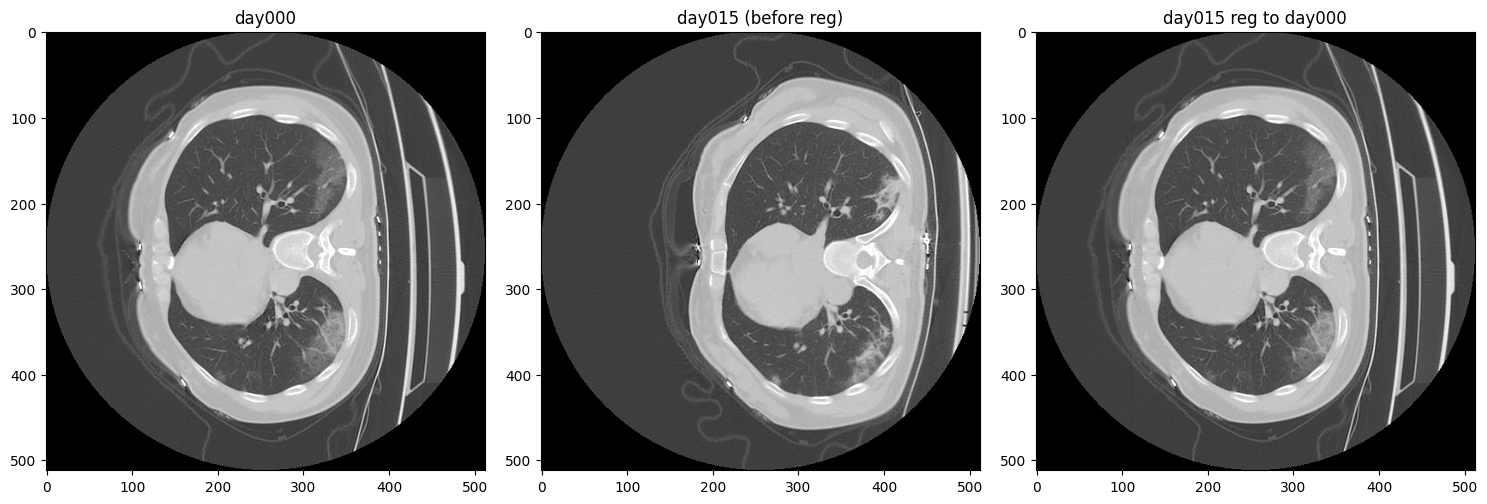

In [12]:
plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(ct_base[:,:,30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day000')

plt.subplot(132)
plt.imshow(ct_FU[:,:,30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day015 (before reg)')

plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30], vmin=-1500, vmax=500, cmap='gray')
plt.title('day015 reg to day000')

plt.tight_layout()
plt.show()

정렬 후 비교했을 때, 폐 하부 부분이 day0보다 day15에서 넓고 진해진 것으로 보인다.

###2. 실습코드02: Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기

(256, 256) uint8


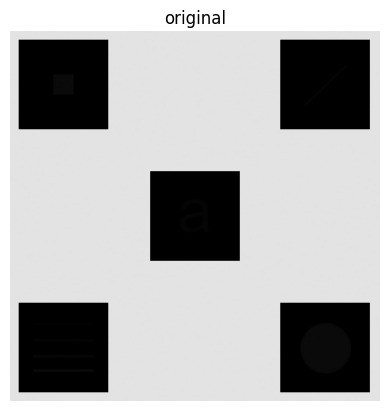

In [38]:
f = plt.imread(imgpath + '/hidden-symbols.tif')
print(f.shape, f.dtype)

plt.imshow(f, vmin=0, vmax=255, cmap='gray')
plt.axis('off')
plt.title('original')
plt.show()

In [39]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

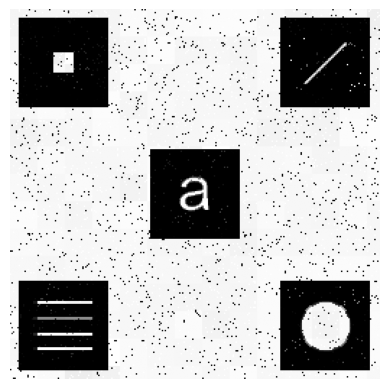

In [40]:
N = 19
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

###3. 실습코드02: Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [41]:
import scipy.signal as signal
from skimage import io
import time

In [52]:
f = io.imread('/content/drive/MyDrive/4659.JPEG', as_gray=True)
print(f.shape, f.dtype)

(1440, 1080) float64


In [53]:
f = f[::2, ::2]
print(f.shape)

(720, 540)


computation time =  0.03510308265686035  sec


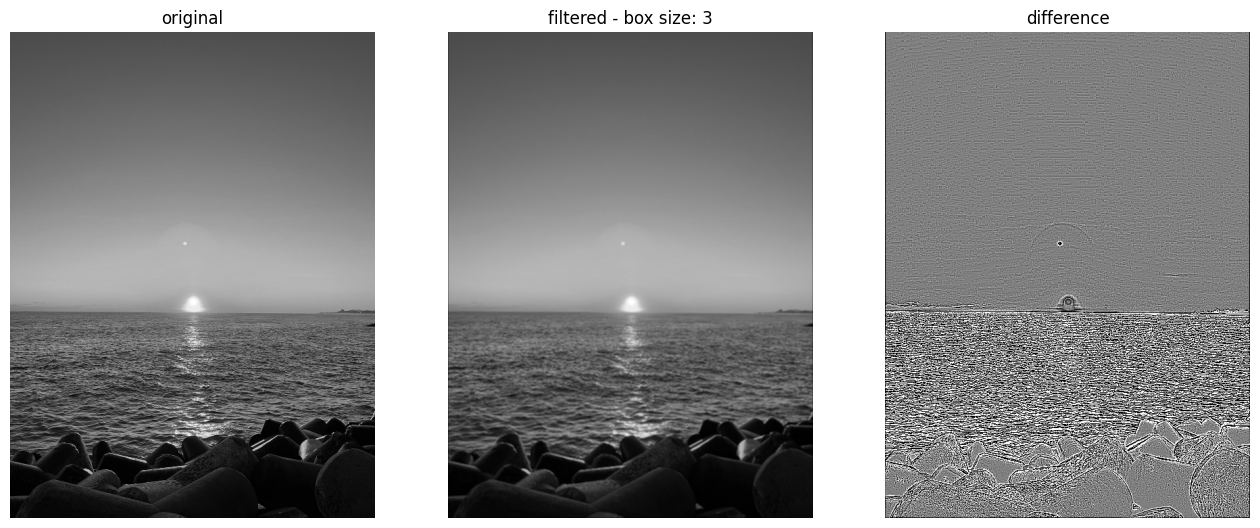

computation time =  0.11655926704406738  sec


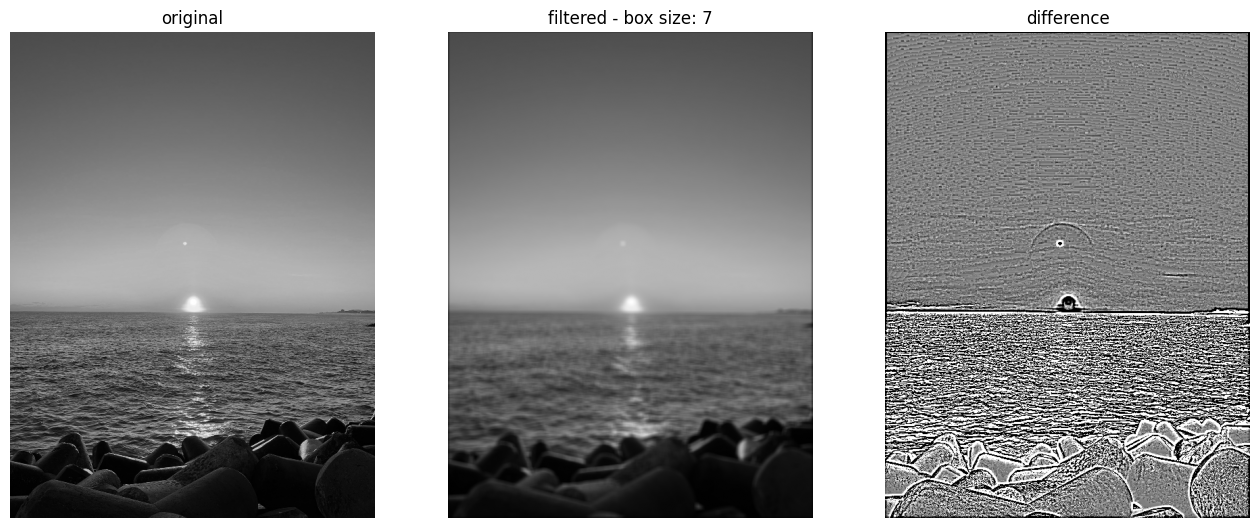

computation time =  0.40348291397094727  sec


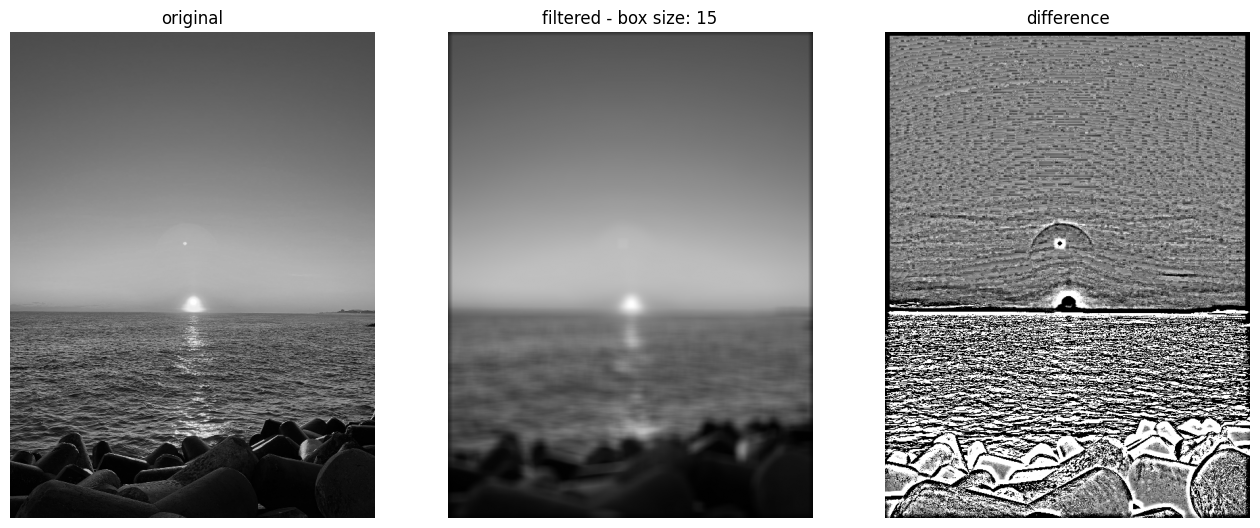

computation time =  1.3671603202819824  sec


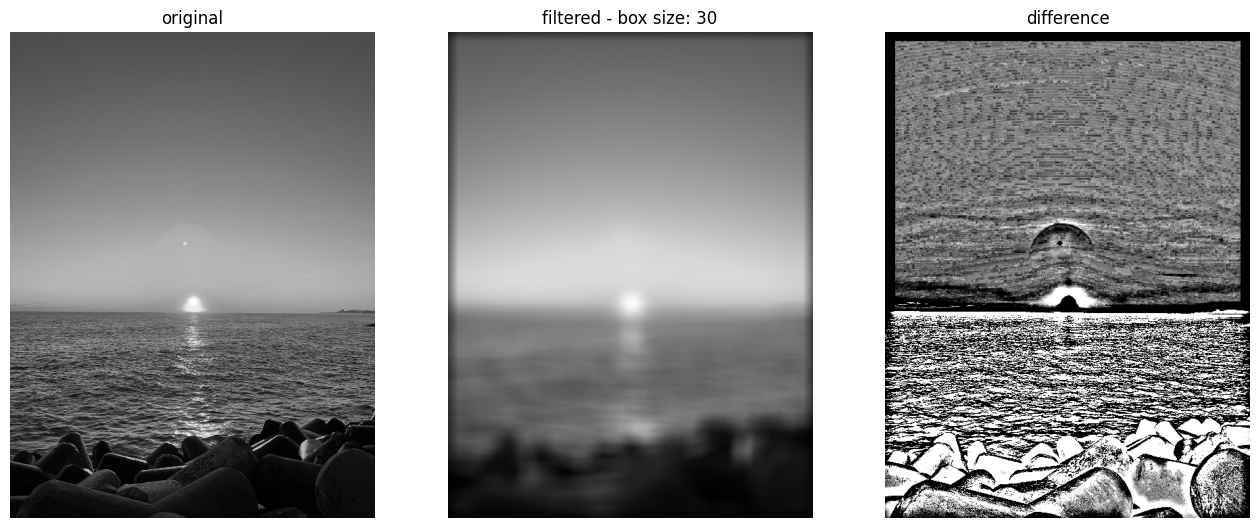

In [54]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

kernel의 크기를 3, 7, 15, 30으로 키울수록 영상이 점점 흐려진다.

연산시간은 0.035초(3×3 kernel)에서 1.367초(30×30 kernel)로 증가했다.

###4. 실습코드02: Exercise 3. Blurring이 발생한 사진을 가져와서 적당한 HPF결과를 활용하여 sharpening을 진행하기

In [64]:
f = io.imread('/content/drive/MyDrive/IMG_0660.jpeg', as_gray=True)
f = f[::4, ::4]
print(f.shape)

(756, 1008)


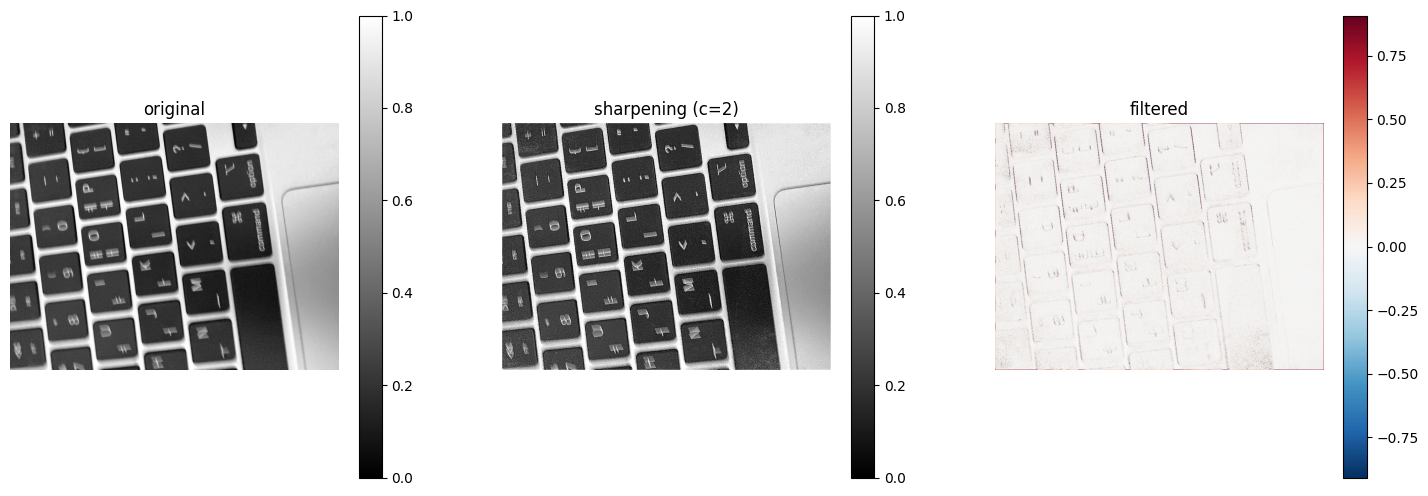

In [81]:
#w2, c = 2

w = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])
y = signal.convolve2d(f, w, mode='same')
c = 2
g = f + c*(y)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f, cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g, cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title(f'sharpening (c={c})')
plt.subplot(133)
plt.imshow(y, cmap='RdBu_r', vmin=-0.5*np.max(np.abs(y)), vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

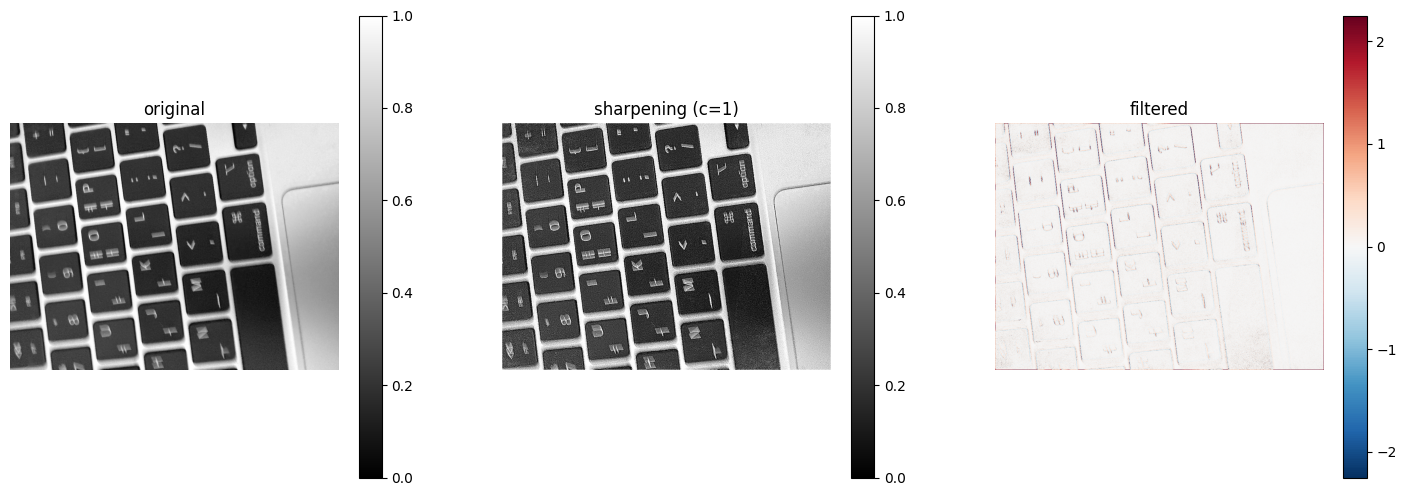

In [80]:
#w4, c = 1

w = np.array([[-1,-1,-1],[-1,8.,-1],[-1,-1,-1]])
y = signal.convolve2d(f, w, mode='same')
c = 1
g = f + c*(y)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f, cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g, cmap='gray', vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title(f'sharpening (c={c})')
plt.subplot(133)
plt.imshow(y, cmap='RdBu_r', vmin=-0.5*np.max(np.abs(y)), vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()